# **Binarization**
## Image Processing and Computer Vision


Binarization is a digital image processing technique that converts a grayscale or color image into a binary image consisting of only two pixel values: black (0) and white (1)

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable

## Manual Binarization

If the objects in the image have different grey levels, we can use the histogram to understand which is the best global threshold to separate the foreground from the background. There are several ways to solve the binarization task in Python

### Python function

The general formula to binarize an image is:
$$
f(v, t) =
\begin{cases}
0 & v < t \\
255 & v \geq t
\end{cases}
$$

Parameters:
- v: value of the pixel
- t: threshold set to binarize the image

The binarization function written in Python implements the formula described early.

In [10]:
def binarization(img, t):
    # Apply thresholding
    binary_img = np.where(img > t,255, 0)
    return binary_img


In order to decide the threshold we study the histogram to find the best value.

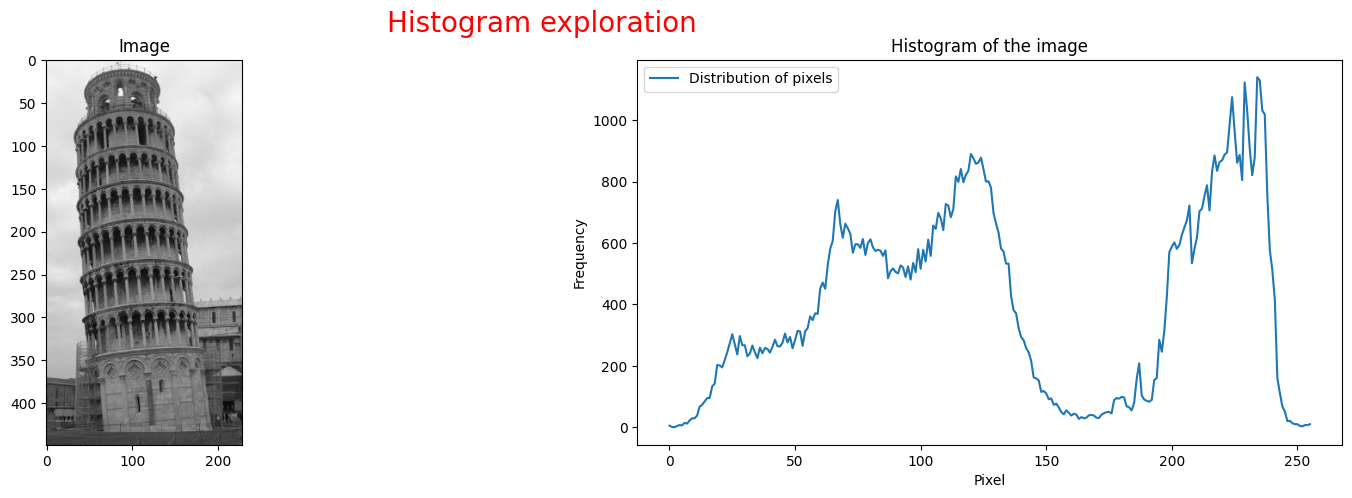

In [7]:
IMG_PATH = "./img/torre.jpg"
img = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
hist_img = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(20, 5))
plt.suptitle("Histogram exploration", fontsize = 20, color = "red")


plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Image")

plt.subplot(1,2,2)
plt.plot(hist_img, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image")
plt.xlabel("Pixel")
plt.ylabel("Frequency")
plt.legend()



We can notice two main groups on the histogram graph:
- left part: it is composed by darker pixels and it represents the towers, the grass and the buildings in the background
- right part: it is composed by lighter pixels and it represents the sky on the image

So if we set the threshold between the groups, we should separate correctly the sky from the rest of the buildings/objects of the image. The chosen value is 160.

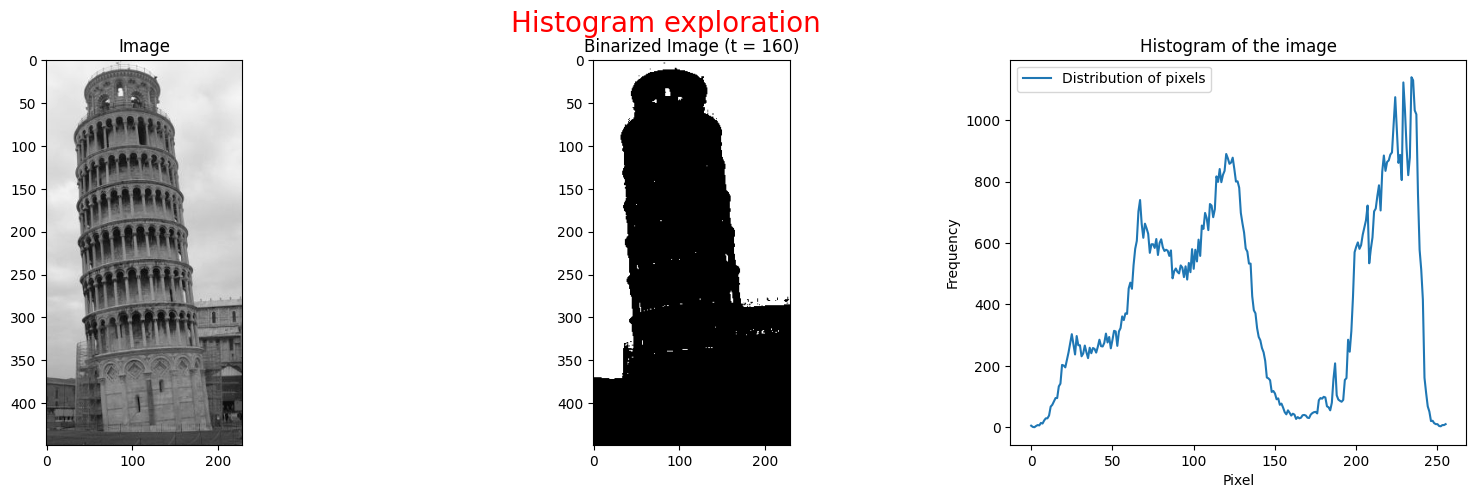

In [17]:
threshold = 160
hist_img = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(20, 5))
plt.suptitle("Histogram exploration", fontsize = 20, color = "red")

binary_img = binarization(img, threshold)

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(binary_img, cmap="gray")
plt.title(f"Binarized Image (t = {threshold})")

plt.subplot(1,3,3)
plt.plot(hist_img, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image")
plt.xlabel("Pixel")
plt.ylabel("Frequency")
plt.legend()



### OpenCV function

In OpenCV we can use **cv2.threshold** to compute the binary image as before:

Syntax:
- retval, dst	=	cv.threshold(	src, thresh, maxval, type[, dst]	)


Parameters:
- src: input array (multiple-channel, 8-bit or 32-bit floating point).
- dst: output array of the same size and type and the same number of channels as src.
- thresh: threshold value.
- maxval: maximum value to use with the THRESH_BINARY and THRESH_BINARY_INV thresholding types.
- type: thresholding type (see ThresholdTypes).

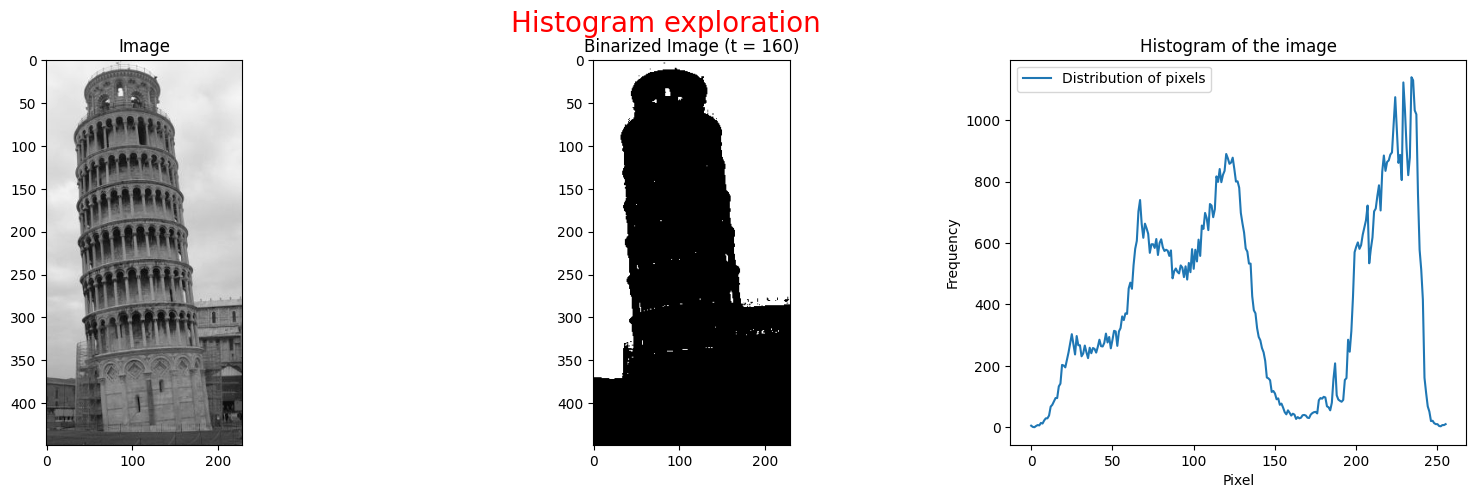

In [18]:
threshold = 160
hist_img = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(20, 5))
plt.suptitle("Histogram exploration", fontsize = 20, color = "red")

_, binary_img = cv2.threshold(img, threshold, 255, cv2.THRESH_BINARY)

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(binary_img, cmap="gray")
plt.title(f"Binarized Image (t = {threshold})")

plt.subplot(1,3,3)
plt.plot(hist_img, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image")
plt.xlabel("Pixel")
plt.ylabel("Frequency")
plt.legend()



## Automatic Binarization

There are ways to compute automaticcaly the optimal threshold for the task

### Otsu method 

In OpenCV we can use **cv2.threshold** to compute the binary image using **Otsu method**: it automatically finds the **global threshold** in the histogram that minimize the intra-class variance of the pixel's intensity of the foreground and background determined by the threshold itseld

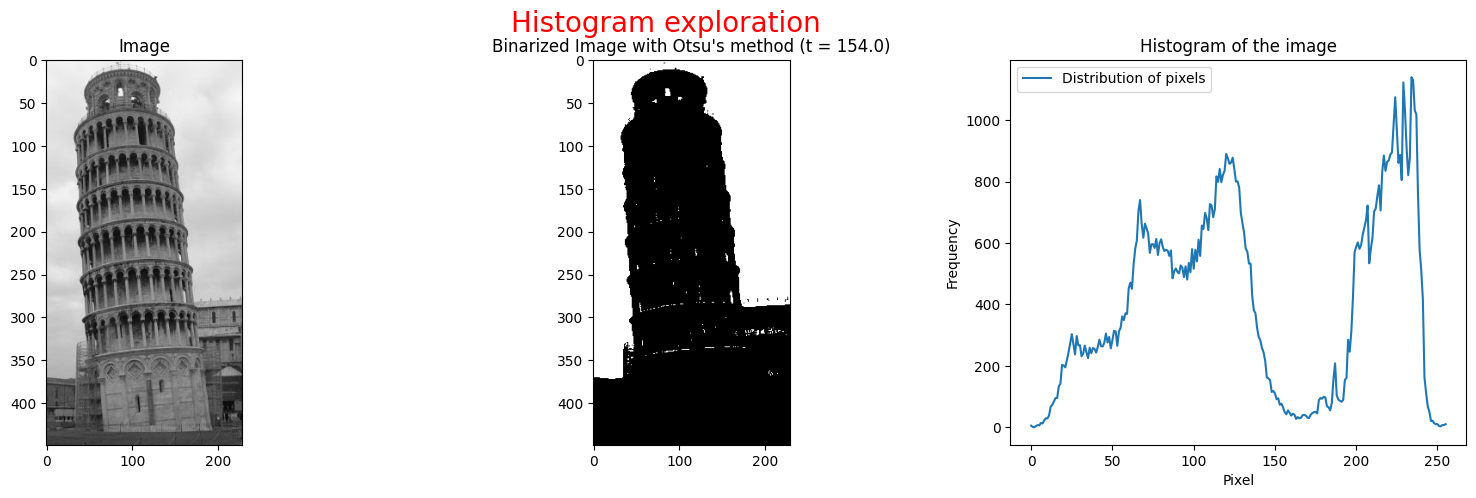

In [ ]:
hist_img = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(20, 5))
plt.suptitle("Histogram exploration", fontsize = 20, color = "red")

t, binary_img = cv2.threshold(img, -1, 255, cv2.THRESH_OTSU)

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(binary_img, cmap="gray")
plt.title(f"Binarized Image with Otsu's method (t = {t})")

plt.subplot(1,3,3)
plt.plot(hist_img, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image")
plt.xlabel("Pixel")
plt.ylabel("Frequency")
plt.legend()


### Local threshold 

If the objects and background are not uniform, it is not possible to determine an optimal global threshold that separates the foreground and background distinctly (for example due to non-uniform illumination).

To solve the inability of the global thresholding to handle images with varying lighting conditions we can adopt a **local (or adaptive) threshold**. Adaptive thresholding solve this problem calculating the threshold for small regions around each pixel. 

Syntax:
- cv.adaptiveThreshold(	src, maxValue, adaptiveMethod, thresholdType, blockSize, C[, dst]	) ->	dst

Parameters:
- src: source 8-bit single-channel image.
- dst: destination image of the same size and the same type as src.
- maxValue: non-zero value assigned to the pixels for which the condition is satisfied
- adaptiveMethod: Adaptive thresholding algorithm to use, see AdaptiveThresholdTypes. The BORDER_REPLICATE | BORDER_ISOLATED is used to process boundaries.
- Thresholding: type that must be either THRESH_BINARY or THRESH_BINARY_INV, see ThresholdTypes.
- blockSize: size of a pixel neighborhood that is used to calculate a threshold value for the pixel: 3, 5, 7, and so on.
- C: constant subtracted from the mean or weighted mean (see the details below). Normally, it is positive but may be zero or negative as well.

The adaptiveMethod decides how the threshold value is calculated:
- cv.ADAPTIVE_THRESH_MEAN_C: the threshold value is the mean of the neighbourhood area minus the constant C.
- cv.ADAPTIVE_THRESH_GAUSSIAN_C: the threshold value is a gaussian-weighted sum of the neighbourhood values minus the constant C.

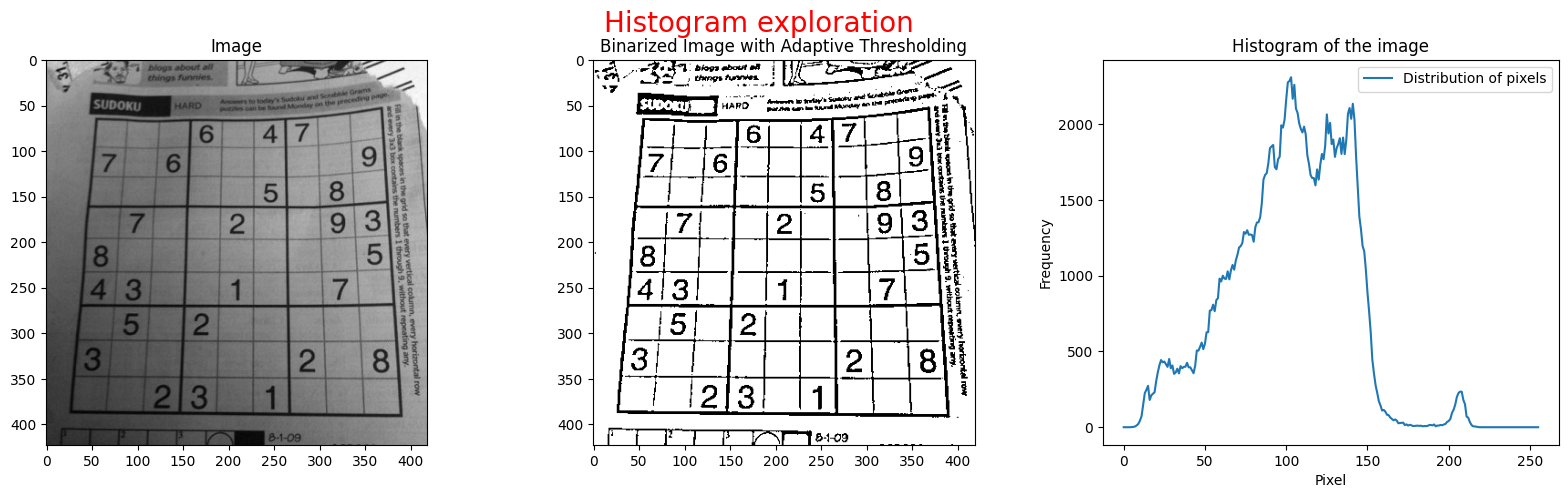

In [ ]:
IMG_PATH = "./img/sudoku.jpg"
img = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
hist_img = cv2.calcHist([img], [0], None, [256], [0, 256])

plt.figure(figsize=(20, 5))
plt.suptitle("Histogram exploration", fontsize = 20, color = "red")

binary_img = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 10)

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(binary_img, cmap="gray")
plt.title(f"Binarized Image with Adaptive Thresholding")

plt.subplot(1,3,3)
plt.plot(hist_img, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image")
plt.xlabel("Pixel")
plt.ylabel("Frequency")
plt.legend()




Text(0.5, 1.0, 'Histogram of the image blue channel')

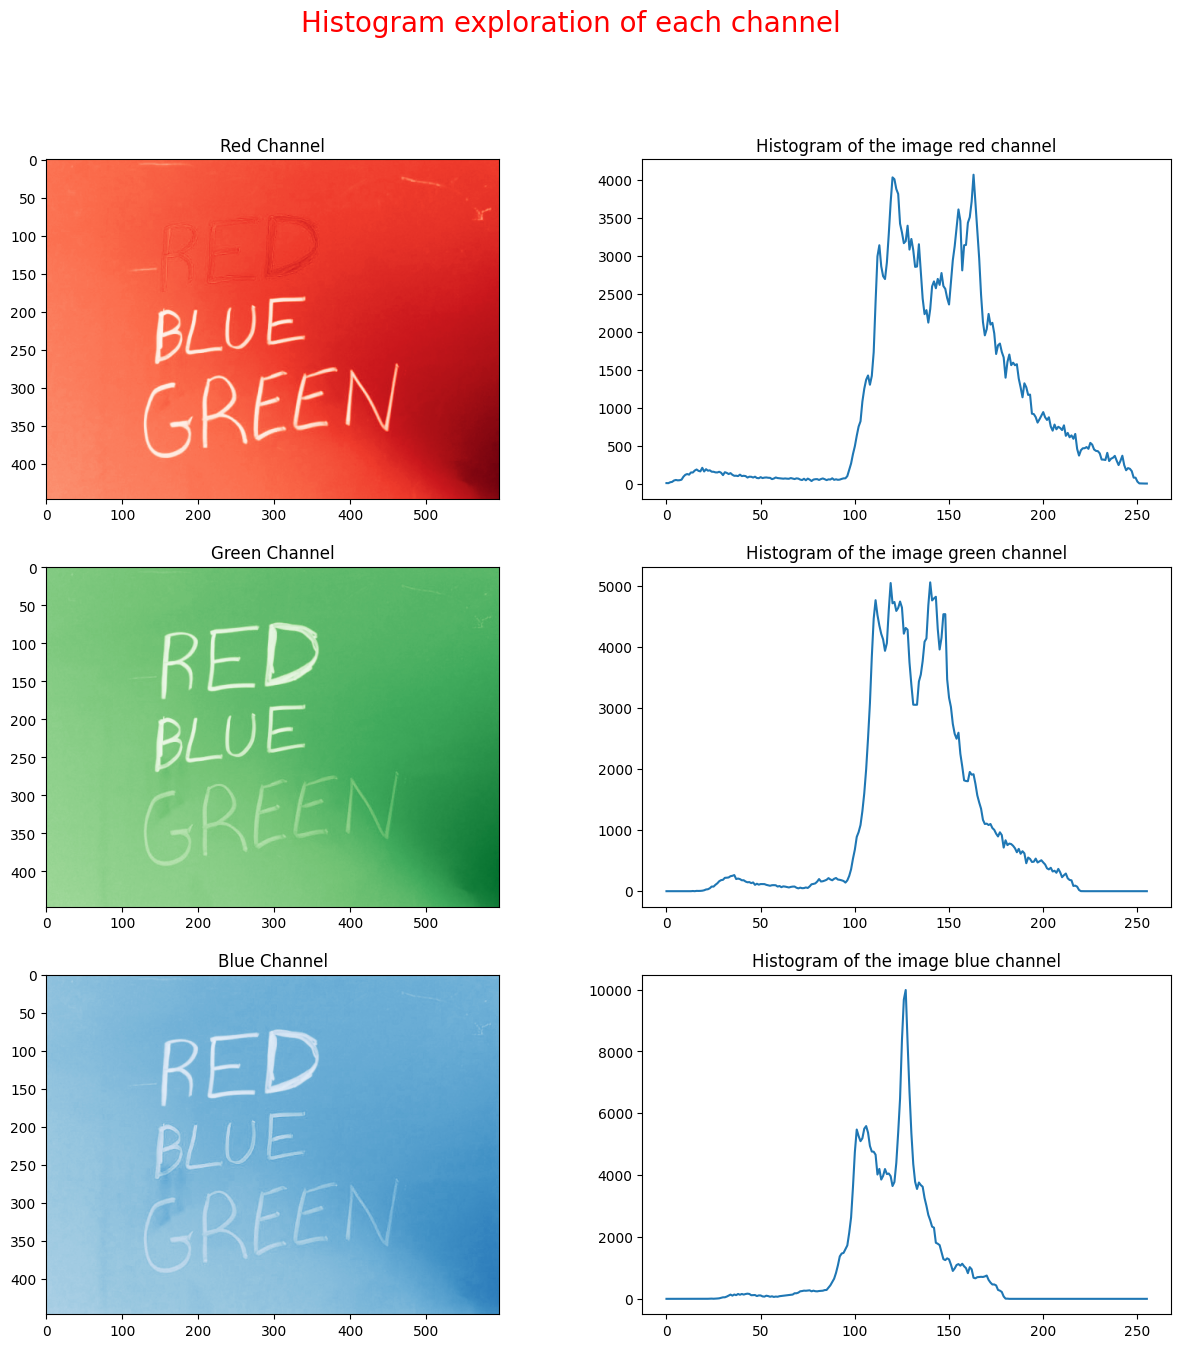

In [33]:
IMG_PATH_RGB = "./img/red_blue_green.jpg"

# Read the RGB image and convert it to grayscale to apply direct binarization
#img_rgb = cv2.imread(IMG_PATH_RGB)
#img = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)

# Read the RGB image and apply binarization to each channel separately
img_rgb = cv2.imread(IMG_PATH_RGB)
img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB) # Convert the color space from BGR to RGB
r,g,b = cv2.split(img_rgb)

hist_r = cv2.calcHist([r], [0], None, [256], [0, 256])
hist_g = cv2.calcHist([g], [0], None, [256], [0, 256])
hist_b = cv2.calcHist([b], [0], None, [256], [0, 256])

plt.figure(figsize=(15, 15))
plt.suptitle("Histogram exploration of each channel", fontsize = 20, color = "red")

plt.subplot(3,2,1)
plt.imshow(r, cmap="Reds", vmin=0, vmax=255)
plt.title("Red Channel")

plt.subplot(3,2,2)
plt.plot(hist_r, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image red channel")

plt.subplot(3,2,3)
plt.imshow(g, cmap="Greens", vmin=0, vmax=255)
plt.title("Green Channel")

plt.subplot(3,2,4)
plt.plot(hist_g, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image green channel")

plt.subplot(3,2,5)
plt.imshow(b, cmap="Blues", vmin=0, vmax=255)
plt.title("Blue Channel")

plt.subplot(3,2,6)
plt.plot(hist_b, label = "Distribution of pixels", alpha = 1)
plt.title("Histogram of the image blue channel")


Text(0.5, 1.0, 'Binary Blue Channel')

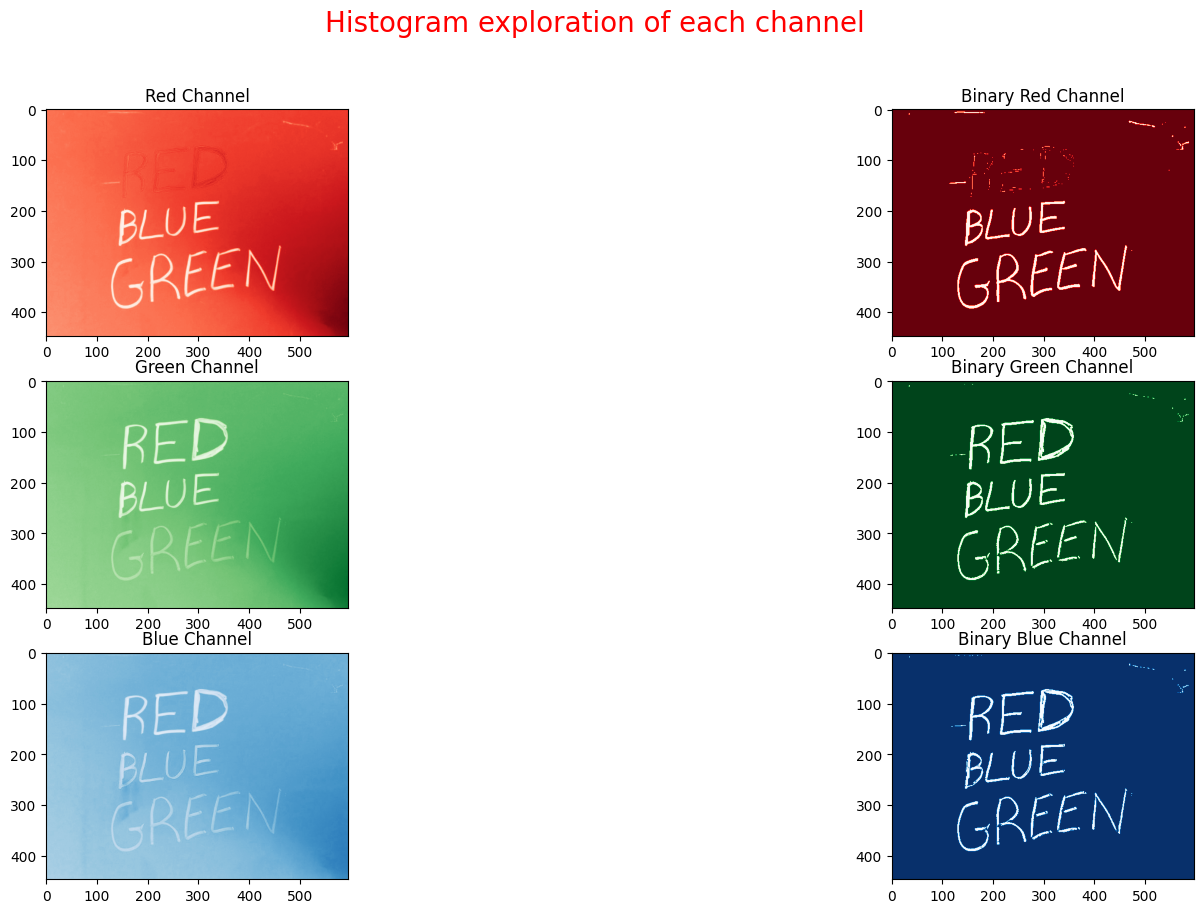

In [27]:
IMG_PATH_RGB = "./img/red_blue_green.jpg"

# Read the RGB image and convert it to grayscale to apply direct binarization
#img_rgb = cv2.imread(IMG_PATH_RGB)
#img = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)

# Read the RGB image and apply binarization to each channel separately
img_rgb = cv2.imread(IMG_PATH_RGB)
img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB) # Convert the color space from BGR to RGB
r,g,b = cv2.split(img_rgb)

binary_img_r = cv2.adaptiveThreshold(r, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 10)
binary_img_g = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 10)
binary_img_b = cv2.adaptiveThreshold(b, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 10)

plt.figure(figsize=(20, 10))
plt.suptitle("Histogram exploration of each channel", fontsize = 20, color = "red")

plt.subplot(3,2,1)
plt.imshow(r, cmap="Reds", vmin=0, vmax=255)
plt.title("Red Channel")

plt.subplot(3,2,2)
plt.imshow(binary_img_r, cmap="Reds", vmin=0, vmax=255)
plt.title("Binary Red Channel")

plt.subplot(3,2,3)
plt.imshow(g, cmap="Greens", vmin=0, vmax=255)
plt.title("Green Channel")

plt.subplot(3,2,4)
plt.imshow(binary_img_g, cmap="Greens", vmin=0, vmax=255)
plt.title("Binary Green Channel")

plt.subplot(3,2,5)
plt.imshow(b, cmap="Blues", vmin=0, vmax=255)
plt.title("Blue Channel")

plt.subplot(3,2,6)
plt.imshow(binary_img_b, cmap="Blues", vmin=0, vmax=255)
plt.title("Binary Blue Channel")


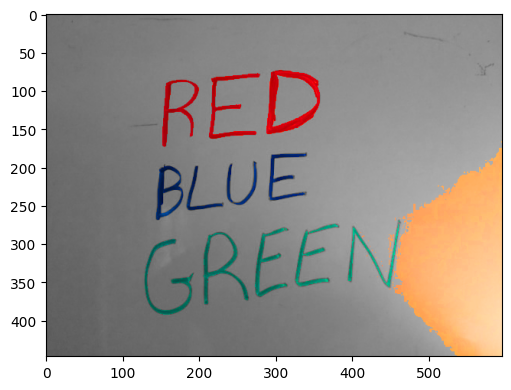

In [38]:
img = cv2.imread(IMG_PATH_RGB)
hls = cv2.cvtColor(img, cv2.COLOR_BGR2HLS)
_,hls[...,2] = cv2.threshold(hls[...,2], -1, 255, cv2.THRESH_OTSU)
res = cv2.cvtColor(hls, cv2.COLOR_HLS2RGB)
plt.figure(figsize=(20, 5))
plt.subplot(1,3,1)
plt.imshow(res)